# 5. Curvature invariants and singularities
$K=R_{abcd}R^{abcd}$ is a coordinate-independent scalar. For Schwarzschild $K=48M^2/r^6$: finite at $r=2M$ (the horizon is only a coordinate singularity of these coordinates) and divergent at $r=0$ (a true curvature singularity). Horizon-regular coordinates make the first point explicit.

Caveat: a single invariant is not a universal singularity detector (e.g. pp-waves have all polynomial invariants zero).

In [1]:
import sympy as sp, numpy as np, matplotlib.pyplot as plt
from gr_from_scratch.spacetimes.schwarzschild import schwarzschild, eddington_finkelstein, M, r, theta
from gr_from_scratch.field_equations.vacuum_equations import compute_geometry
from gr_from_scratch.geometry import invariants as inv

gs = compute_geometry(schwarzschild())
ge = compute_geometry(eddington_finkelstein())
print('K (Schwarzschild coords):', inv.kretschmann(gs.riemann))
print('K (Eddington-Finkelstein):', inv.kretschmann(ge.riemann))
print('EF metric:', ge.metric.g)
print('EF determinant (regular at r=2M):', ge.metric.det)
print('Euler density == K in vacuum:', sp.simplify(inv.euler_density(gs.riemann) - inv.kretschmann(gs.riemann)) == 0)
print('Pontryagin density:', inv.pontryagin_density(gs.riemann))

K (Schwarzschild coords): 48*M**2/r**6


K (Eddington-Finkelstein): 48*M**2/r**6
EF metric: Matrix([[(2*M - r)/r, 1, 0, 0], [1, 0, 0, 0], [0, 0, r**2, 0], [0, 0, 0, r**2*sin(theta)**2]])
EF determinant (regular at r=2M): -r**4*sin(theta)**2


Euler density == K in vacuum: True
Pontryagin density: 0


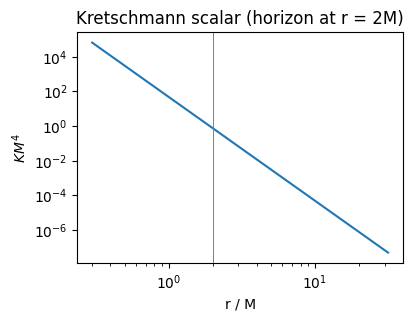

In [2]:
rr = np.logspace(np.log10(0.3), 1.5, 200)
fig, ax = plt.subplots(figsize=(4.2, 3))
ax.loglog(rr, 48 / rr**6)
ax.axvline(2, color='0.5', lw=0.7)
ax.set(xlabel='r / M', ylabel=r'$K M^4$', title='Kretschmann scalar (horizon at r = 2M)')
plt.show()